<a href="https://colab.research.google.com/github/GAEL328530/Lab-pdi-PR-CTICAS/blob/main/Pr%C3%A1ctica_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Práctica 3 - Análisis de color y segmentación con K-Means**

**Objetivo**

Aplicar el algoritmo de clustering k-means para segmentar imágenes en regiones de color similares y analizar los resultados obtenidos al variar el número de clusters.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from google.colab import files

archivos = files.upload()

Saving macarrones.jpg to macarrones.jpg
Saving marcadores.jpg to marcadores.jpg
Saving camaleon.jpg to camaleon.jpg


In [ ]:
def leer_en_rgb(ruta):
    """Lee una imagen con OpenCV y la regresa en orden RGB."""
    img_bgr = cv2.imread(ruta)
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def mostrar(img, titulo, tam=8):
    plt.figure(figsize=(tam, tam))
    plt.imshow(img)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

##**Ejercicio 1. Distribución de colores en el espacio RGB**
El objetivo es observar cómo se distribuyen los colores de una imagen dentro del espacio RGB. Se lee una imagen a color, se extraen las intensidades de cada píxel y se grafican en tres dimensiones con Matplotlib.

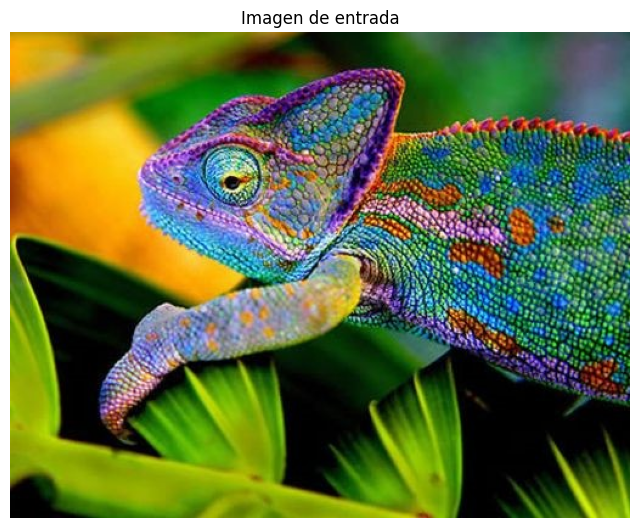

In [ ]:
foto1 = leer_en_rgb("camaleon.jpg")
mostrar(foto1, "Imagen de entrada")

OpenCV guarda los canales en orden BGR, mientras que Matplotlib los espera en RGB; por eso se hace la conversión antes de mostrar la imagen y así los colores se ven como deben.

In [ ]:
datos_rgb = foto1.reshape(-1, 3)

print(f"Total de píxeles en la imagen: {len(datos_rgb)}")
print("Primeros 10 píxeles (R, G, B):")
print(datos_rgb[:10])

Total de píxeles en la imagen: 204000
Primeros 10 píxeles (R, G, B):
[[188 143   0]
 [189 144   0]
 [190 145   0]
 [191 146   1]
 [190 148   2]
 [189 147   1]
 [188 146   0]
 [188 146   0]
 [187 147   0]
 [187 147   0]]


La imagen pasa de tener forma (alto, ancho, 3) a una tabla de dos dimensiones: cada renglón es un píxel y las tres columnas guardan su nivel de rojo, verde y azul.

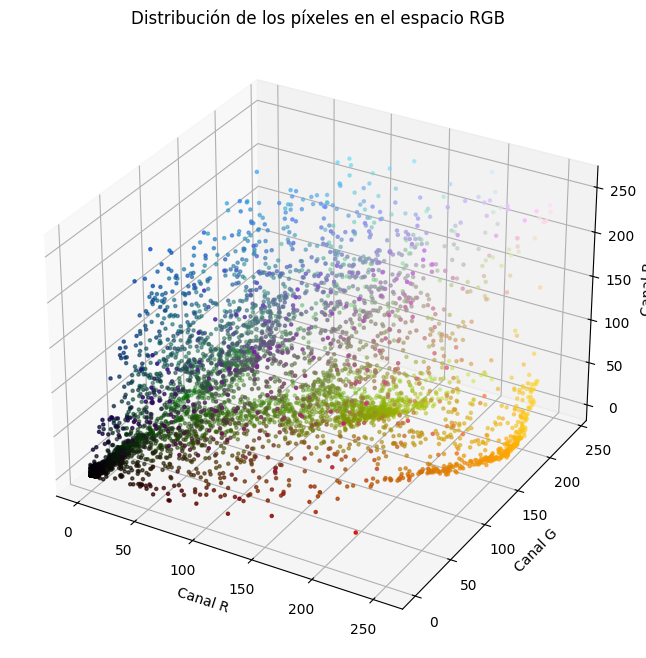

In [ ]:
generador = np.random.default_rng()
indices = generador.choice(len(datos_rgb), size=5000, replace=False)
puntos = datos_rgb[indices]

figura = plt.figure(figsize=(8, 8))
eje3d = figura.add_subplot(projection="3d")

eje3d.scatter(puntos[:, 0], puntos[:, 1], puntos[:, 2],
              c=puntos / 255.0, s=5)

eje3d.set_xlabel("Canal R")
eje3d.set_ylabel("Canal G")
eje3d.set_zlabel("Canal B")
eje3d.set_title("Distribución de los píxeles en el espacio RGB")
plt.show()

Como graficar millones de puntos sería muy lento, se toman 5000 píxeles al azar. Cada punto se dibuja en la posición de sus valores (R, G, B) y con su propio color, de modo que se aprecia qué tonos predominan en la imagen.

##**Ejercicio 2. Segmentación por color con K-Means**
K-Means agrupa los píxeles según la similitud de su color. Se prueban varios valores de k para comparar qué tan detallada queda la segmentación.

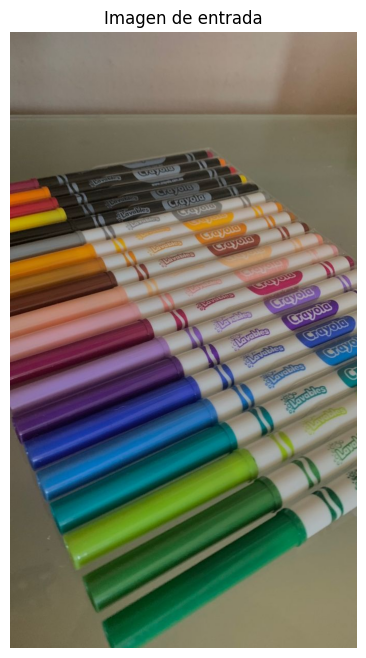

In [ ]:
foto2 = leer_en_rgb("marcadores.jpg")
mostrar(foto2, "Imagen de entrada")

Se acomodan los píxeles en una tabla y se convierten a punto flotante, que es el tipo de dato que pide cv2.kmeans.

In [ ]:
muestras2 = np.float32(foto2.reshape(-1, 3))

In [ ]:
def aplicar_kmeans(img, muestras, num_grupos):
    """Agrupa los píxeles en num_grupos colores y muestra el resultado."""
    parada = (cv2.TERM_CRITERIA_MAX_ITER + cv2.TERM_CRITERIA_EPS, 100, 0.2)

    _, grupo_de_cada_pixel, centroides = cv2.kmeans(
        muestras, num_grupos, None, parada,
        10, cv2.KMEANS_RANDOM_CENTERS
    )

    paleta = centroides.astype(np.uint8)
    img_segmentada = paleta[grupo_de_cada_pixel.ravel()].reshape(img.shape)

    mostrar(img_segmentada, f"K-Means con {num_grupos} grupos", tam=6)

    print(f"Centroides (color promedio de cada grupo) para k = {num_grupos}:")
    print(paleta)
    return img_segmentada

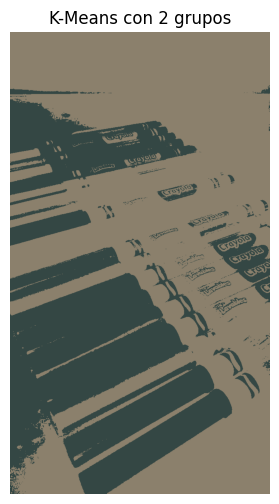

Centroides (color promedio de cada grupo) para k = 2:
[[ 52  71  68]
 [139 128 108]]


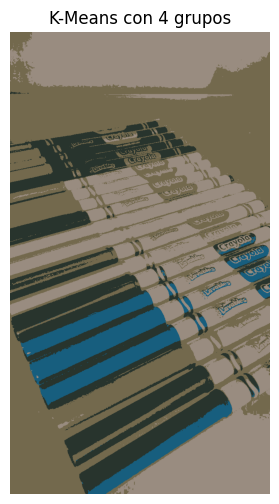

Centroides (color promedio de cada grupo) para k = 4:
[[ 23  94 126]
 [115 105  77]
 [ 40  52  45]
 [153 140 128]]


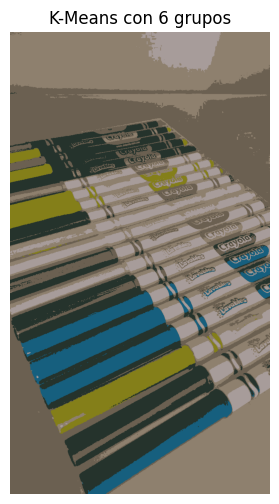

Centroides (color promedio de cada grupo) para k = 6:
[[107  96  81]
 [167 156 154]
 [132 127  25]
 [ 22  95 126]
 [ 37  51  44]
 [142 128 110]]


In [ ]:
for k in (2, 4, 6):
    aplicar_kmeans(foto2, muestras2, k)

Cada píxel se asigna al grupo cuyo centroide tiene el color más parecido. Después se reemplaza cada píxel por el color de su centroide, lo que genera una versión de la imagen con solo k colores. Mientras mayor es k, más detalles se conservan.

##**Ejercicio 3. Caso práctico**
Se usa una imagen que contiene varios objetos de distintos colores, y con K-Means se separan sus regiones principales para ver cómo el algoritmo distingue los elementos de forma automática.

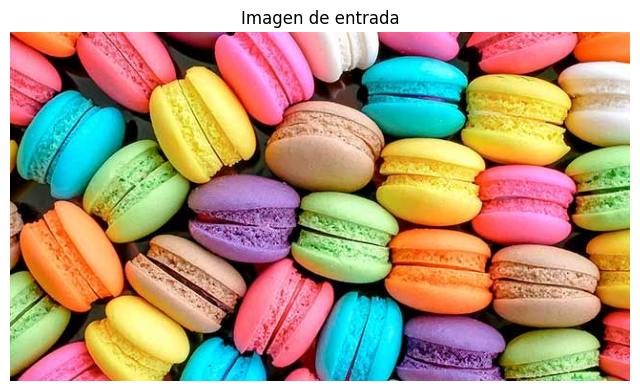

In [ ]:
foto3 = leer_en_rgb("macarrones.jpg")
mostrar(foto3, "Imagen de entrada")

muestras3 = np.float32(foto3.reshape(-1, 3))

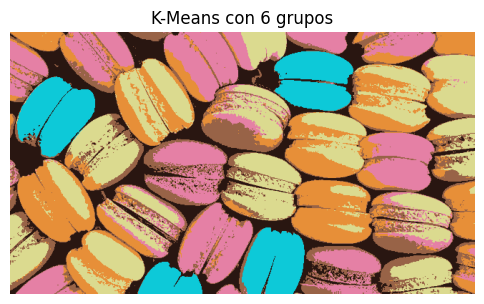

Centroides (color promedio de cada grupo) para k = 6:
[[229 128 165]
 [ 41  22  17]
 [ 13 201 216]
 [152  99  71]
 [231 143  56]
 [219 218 143]]


array([[[231, 143,  56],
        [231, 143,  56],
        [231, 143,  56],
        ...,
        [231, 143,  56],
        [231, 143,  56],
        [231, 143,  56]],

       [[152,  99,  71],
        [231, 143,  56],
        [231, 143,  56],
        ...,
        [231, 143,  56],
        [231, 143,  56],
        [231, 143,  56]],

       [[ 41,  22,  17],
        [152,  99,  71],
        [152,  99,  71],
        ...,
        [231, 143,  56],
        [231, 143,  56],
        [231, 143,  56]],

       ...,

       [[ 41,  22,  17],
        [ 41,  22,  17],
        [ 41,  22,  17],
        ...,
        [231, 143,  56],
        [231, 143,  56],
        [231, 143,  56]],

       [[ 41,  22,  17],
        [ 41,  22,  17],
        [ 41,  22,  17],
        ...,
        [152,  99,  71],
        [231, 143,  56],
        [231, 143,  56]],

       [[ 41,  22,  17],
        [ 41,  22,  17],
        [ 41,  22,  17],
        ...,
        [152,  99,  71],
        [152,  99,  71],
        [152,  99,  71]]], shape=(366, 650, 3), dtype=uint8)
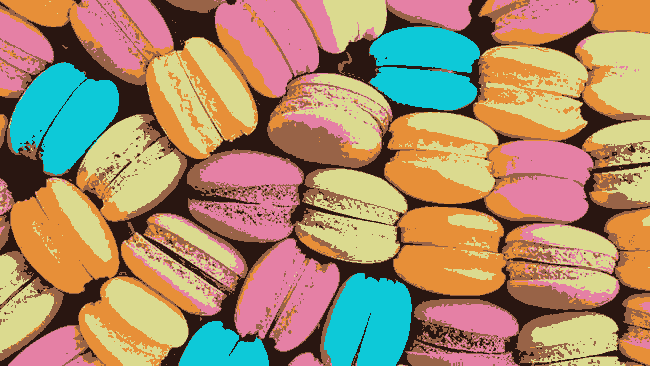

In [ ]:
aplicar_kmeans(foto3, muestras3, 6)

Con k = 6 el algoritmo encuentra seis colores dominantes. Cada región de la imagen queda pintada con el color promedio de su grupo, así que los objetos y el fondo se diferencian con claridad.